In [ ]:
from fenics import *
import numpy as np
from ufl import nabla_grad, sym, as_tensor
from scipy.optimize import root_scalar

In [39]:
from fenics import *
from ufl import nabla_grad, sym, as_tensor

# ----------------------------
# 1) User choice: material and geometry
# ----------------------------
material_type = 'orthotropic'  # 'isotropic' or 'orthotropic'

# Beam geometry (mm)
L_beam = 100.0   # total length
w      = 20.0   # height (depth in plane)
t      = 10    # thickness (out‐of‐plane)

rho = 7.85e-3  # Density (g/mm³ → N/mm³)
g = 9.81  # Acceleration due to gravity (m/s² → mm/s²)

# Applied (downward) point force at mid‐span (N)
#   — if you want 2544 N downward, use F_point = -2544.0
F_point = -1830.0

# ----------------------------
# 2) Material properties (N/mm²)
# ----------------------------
if material_type == 'isotropic':
    E  = 52e3    # Young's modulus (GPa → N/mm²)
    nu = 0.3
    # plane‐stress constitutive relationship
    def sigma_tensor(u):
        eps = sym(nabla_grad(u))
        return as_tensor([[ E/(1 - nu**2)*(eps[0,0] + nu*eps[1,1]),
                             E/(1 + nu)*eps[0,1] ],
                          [ E/(1 + nu)*eps[1,0],
                             E/(1 - nu**2)*(eps[1,1] + nu*eps[0,0]) ]])
elif material_type == 'orthotropic':
    Q11, Q22, Q12, Q66 = 41e3, 10.3e3, 3.1e3, 4e3
    def sigma_tensor(u):
        eps = sym(nabla_grad(u))
        return as_tensor([[ Q11*eps[0,0] + Q12*eps[1,1],      2*Q66*eps[0,1] ],
                          [      2*Q66*eps[1,0], Q12*eps[0,0] + Q22*eps[1,1] ]])
else:
    raise ValueError("material_type must be 'isotropic' or 'orthotropic'")

# ----------------------------
# 3) Mesh and FunctionSpace
# ----------------------------
# You can adjust dnx, dny to refine/coarsen
dnx, dny = 330, 100
mesh = RectangleMesh(Point(0.0, 0.0), Point(L_beam, w), dnx, dny)
V = VectorFunctionSpace(mesh, 'P', 1)

# ----------------------------
# 4) Mark supports (simply supported at x=0 and x=L_beam)
#    → zero vertical displacement u_y at both ends,
#      no horizontal constraint (roller supports in y‐direction only).
# ----------------------------
tol = 1e-8

def left_support(x, on_boundary):
    return on_boundary and near(x[0], 0.0, tol)

def right_support(x, on_boundary):
    return on_boundary and near(x[0], L_beam, tol)

bcs = [
    # u_y = 0 at x=0
    DirichletBC(V.sub(1), Constant(0.0), left_support),
    # u_x = 0 at x=0
    DirichletBC(V.sub(0), Constant(0.0), left_support),
    # # u_y = 0 at x=L_beam
    # DirichletBC(V.sub(1), Constant(0.0), right_support),
    # # u_x = 0 at x=L_beam
    # DirichletBC(V.sub(0), Constant(0.0), right_support)
]

# ----------------------------
# 5) Variational forms (linear elasticity, plane stress)
# ----------------------------
u = TrialFunction(V)
v = TestFunction(V)

a = inner(sigma_tensor(u), sym(nabla_grad(v))) * dx
# Gravity force: body force in the negative y-direction
gravity_force = Constant((0.0, -rho * g))

# Right-hand side form including gravity
L_form = dot(gravity_force, v) * dx

# Assemble stiffness matrix and RHS vector
A = assemble(a)
b = assemble(L_form)

# ----------------------------
# 6) Apply point‐load at mid‐span via PointSource
#    We put a concentrated vertical force F_point at (L_beam/2, w) on the u_y component.
# ----------------------------
# mid_pt = Point(L_beam/2.0, w)
# point_source = PointSource(V.sub(1), mid_pt, F_point)
# point_source.apply(b)

# ----------------------------
# 7) Apply boundary conditions to (A, b)
# ----------------------------
for bc in bcs:
    bc.apply(A, b)

# ----------------------------
# 8) Solve for u_h
# ----------------------------
u_h = Function(V)
solve(A, u_h.vector(), b)

# ----------------------------
# 9) Post‐process: strains & stresses
# ----------------------------
tensor_space = TensorFunctionSpace(mesh, 'P', 1)

# Strain field: ε = sym(∇u)
strain = project(sym(nabla_grad(u_h)), tensor_space)

# Stress field σ = C : ε
stress = project(sigma_tensor(u_h), tensor_space)

# (Optionally save results, e.g. to XDMF or VTK for Paraview)
# xdmffile_u = XDMFFile("beam_displacement.xdmf")
# xdmffile_u.write(u_h)
# xdmffile_strain = XDMFFile("beam_strain.xdmf")
# xdmffile_strain.write(strain)
# xdmffile_stress = XDMFFile("beam_stress.xdmf")
# xdmffile_stress.write(stress)

print(f"Solved clamped beam: material = {material_type}")


Solved clamped beam: material = orthotropic


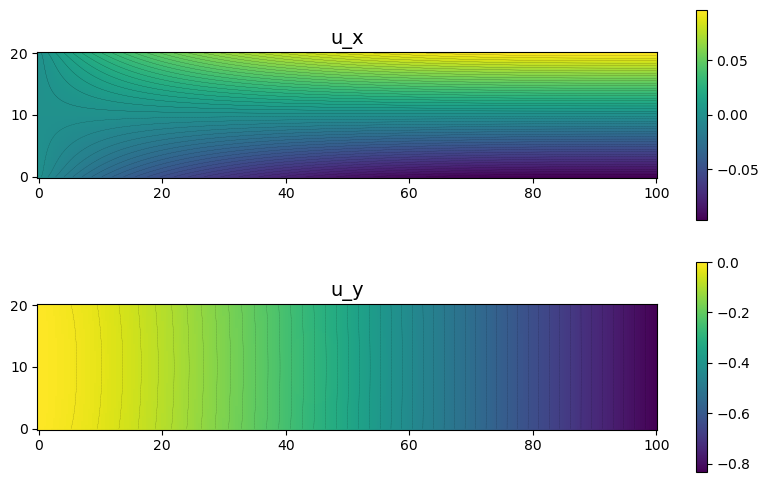

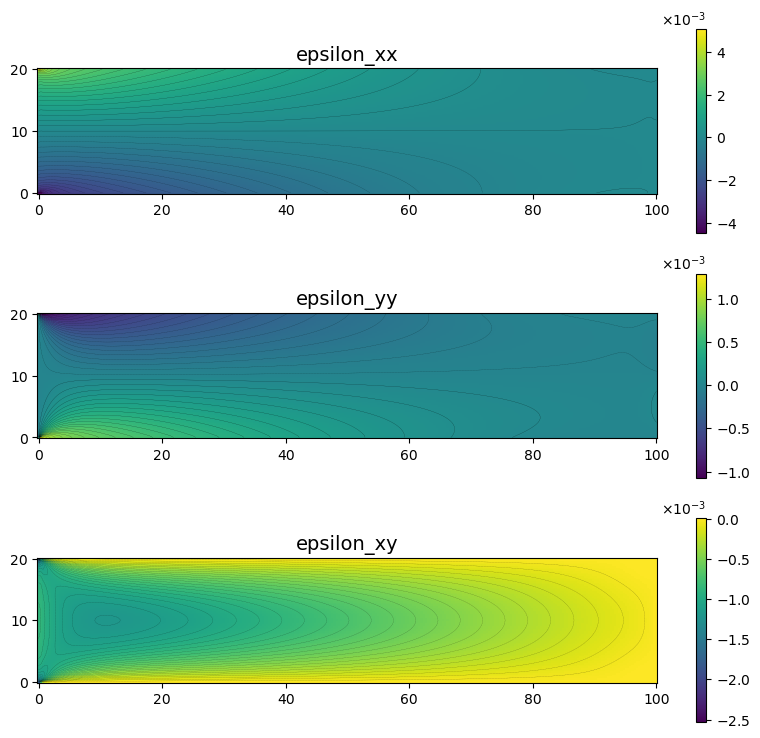

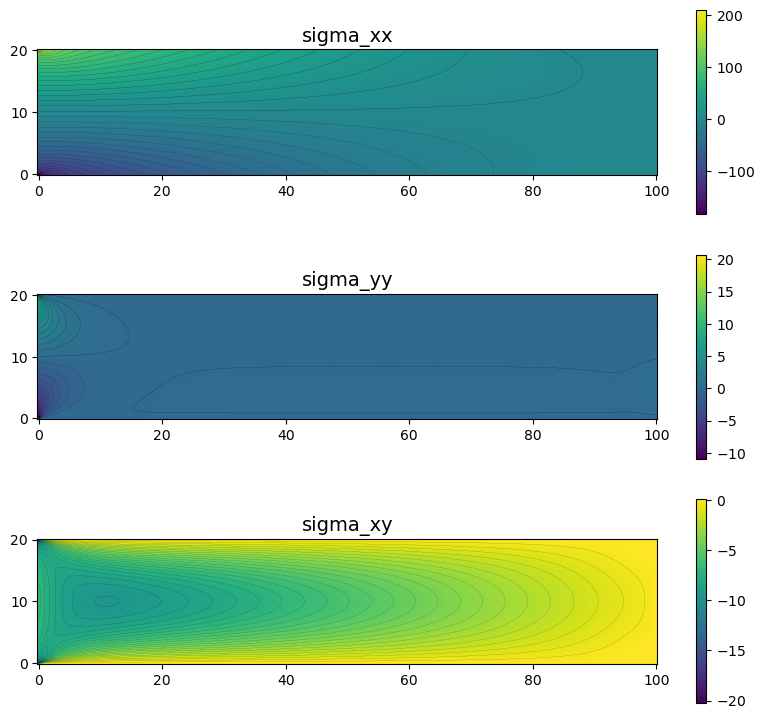

Text(0, 0.5, 'Syy integral (N/mm)')

<Figure size 640x480 with 0 Axes>

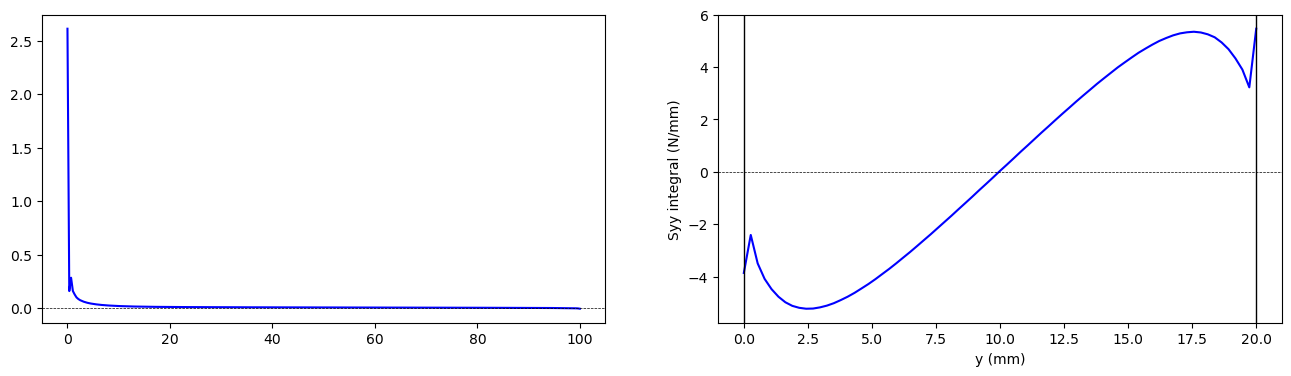

In [41]:
import numpy as np
from matplotlib.colors import ListedColormap
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt


def pcolor_plot(AX, X, Y, C, title, colormap="viridis", set_axis='on', colorbar=True, contour=True, n_levels=50, **kwargs):
    """
    Plots a pcolor plot with optional contour lines.
    
    Parameters:
        AX (matplotlib.axes): The axis to plot on.
        X, Y (2D array): Grid coordinates.
        C (2D array): Scalar field to plot.
        title (str): Plot title.
        colormap (str or Colormap): Colormap to use.
        set_axis (str): 'on' or 'off' to control axis visibility.
        colorbar (bool): Whether to display a colorbar.
        contour (bool): If True, adds contour lines.
        n_levels (int): Number of contour levels.
        kwargs: Optional `cmin` and `cmax` for color limits.
    """
    formatter = ticker.ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-3, 3))

    cmin = kwargs.get("cmin", None)
    cmax = kwargs.get("cmax", None)

    im = AX.pcolormesh(X, Y, C, cmap=colormap, shading='auto', vmin=cmin, vmax=cmax)

    if contour:
        levels = np.linspace(np.min(C) if cmin is None else cmin,
                             np.max(C) if cmax is None else cmax,
                             n_levels)
        AX.contour(X, Y, C, levels=levels, colors='k', linewidths=0.1)

    AX.set_aspect("equal", "box")
    AX.axis(set_axis)
    AX.set_title(title, fontsize=14)

    if colorbar:
        fig = AX.get_figure()
        fig.colorbar(im, ax=AX, format=formatter)

    return im

cmap = plt.get_cmap('viridis')
num_colors = 30
color_values = [cmap(i) for i in np.linspace(0, 1, num_colors)]
cmap = ListedColormap(color_values)
cmap = "viridis"

n_plot = (285, 75)
full_region = True

x_plot = np.linspace(0, L_beam, n_plot[0]) if full_region else np.linspace(0, L_beam, n_plot[0] // 2)
y_plot = np.linspace(0, w, n_plot[1])
X, Y = np.meshgrid(x_plot, y_plot)

X_grid = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

u_val = np.array([u_h(X_grid[i, :]) for i in range(X_grid.shape[0])])
strain_val = np.array([strain(X_grid[i, :]) for i in range(X_grid.shape[0])])
strain_val = np.array([strain_val[:,0], strain_val[:,3], 0.5*(strain_val[:,1]+strain_val[:,2])]).T
stress_val = np.array([stress(X_grid[i, :]) for i in range(X_grid.shape[0])])
stress_val = np.array([stress_val[:,0], stress_val[:,3], 0.5*(stress_val[:,1]+stress_val[:,2])]).T

fig_len = 3 if full_region else 6 
fig_size = (10 ,fig_len * 2) if full_region else (2 * fig_len, 3)
n_subplot = (2, 1) if full_region else (1, 2)

# # Plot displacement
fig, ax = plt.subplots(n_subplot[0], n_subplot[1], figsize=fig_size)
im = pcolor_plot(ax[0], X, Y, u_val[:,0].reshape(X.shape), "u_x",colormap=cmap)
im = pcolor_plot(ax[1], X, Y, u_val[:,1].reshape(X.shape), "u_y",colormap=cmap)

fig_size = (10 ,fig_len * 3) if full_region else (3 * fig_len, 3)
n_subplot = (3, 1) if full_region else (1, 3)

# # Plot strain
fig, ax = plt.subplots(n_subplot[0], n_subplot[1], figsize=fig_size)
im = pcolor_plot(ax[0], X, Y, strain_val[:, 0].reshape(X.shape), "epsilon_xx", colormap=cmap)
im = pcolor_plot(ax[1], X, Y, strain_val[:, 1].reshape(X.shape), "epsilon_yy", colormap=cmap)
im = pcolor_plot(ax[2], X, Y, strain_val[:, 2].reshape(X.shape), "epsilon_xy", colormap=cmap)

# Plot stress
fig, ax = plt.subplots(n_subplot[0], n_subplot[1], figsize=fig_size)
im = pcolor_plot(ax[0], X, Y, stress_val[:,0].reshape(X.shape), "sigma_xx",colormap=cmap)
im = pcolor_plot(ax[1], X, Y, stress_val[:,1].reshape(X.shape), "sigma_yy",colormap=cmap)
im = pcolor_plot(ax[2], X, Y, stress_val[:,2].reshape(X.shape), "sigma_xy",colormap=cmap)

plt.show()
plt.tight_layout()

# Stress integral of Syy over th height at each x
Syy = stress_val[:,1].reshape(X.shape)
Syy_integral_x = np.trapz(Syy, Y, axis=0)
# Syy_integral_x = np.mean(Syy, axis=0)


# Stress integral of Syy over the width at each y
Syy_integral_y = np.trapz(Syy, X, axis=1)
# Syy_integral_y = np.mean(Syy, axis=1)

# Plot Syy integral
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(X[0,:], Syy_integral_x, label='Syy integral', color='blue')
ax[0].axhline(0, color='black', linestyle='--', linewidth=0.5)
# ax[0].axhline(F_target, color='red', linestyle='--', linewidth=0.5)
# ax[0].axvline(J1S, color='k', linestyle='-', linewidth=1)
# ax[0].axvline(J1L, color='k', linestyle='-', linewidth=1)
# ax[0].axvline(Xmax - J2S, color='k', linestyle='-', linewidth=1)
# ax[0].axvline(Xmax - J2L, color='k', linestyle='-', linewidth=1)
# ax[0].set_xlabel('x (mm)')
# ax[0].set_ylabel('Syy integral (N/mm)')

ax[1].plot(y_plot, Syy_integral_y, label='Syy integral', color='blue')
ax[1].axhline(0, color='black', linestyle='--', linewidth=0.5)
# ax[1].axhline(F_target, color='red', linestyle='--', linewidth=0.5)
ax[1].axvline(0, color='k', linestyle='-', linewidth=1)
ax[1].axvline(w, color='k', linestyle='-', linewidth=1)
ax[1].set_xlabel('y (mm)')
ax[1].set_ylabel('Syy integral (N/mm)')

/tmp/ipykernel_951872/257152021.py:41: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  axs[ind[0]][ind[1]].set_xlim([min(x_bc), max(x_bc)])
/tmp/ipykernel_951872/257152021.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


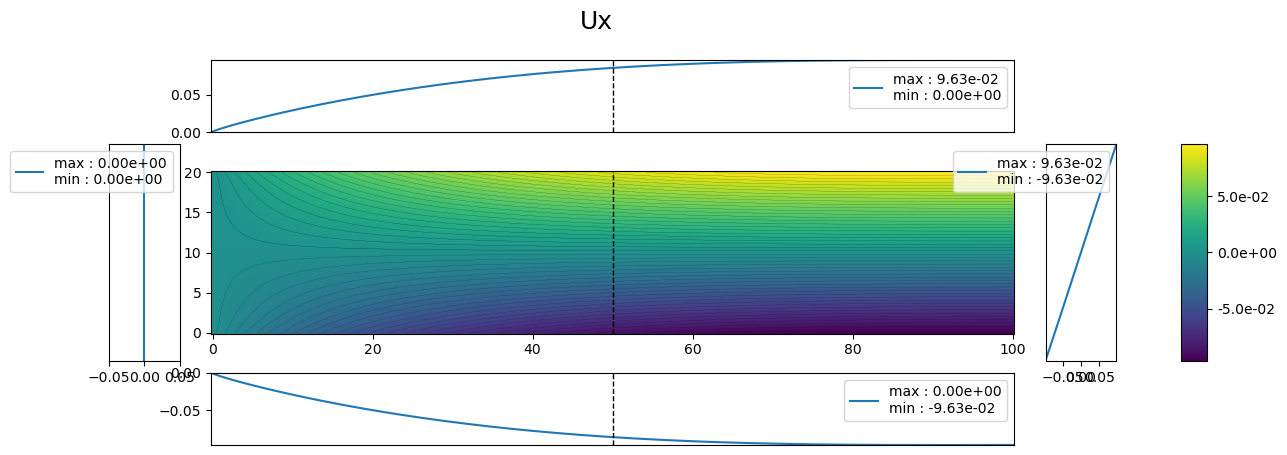

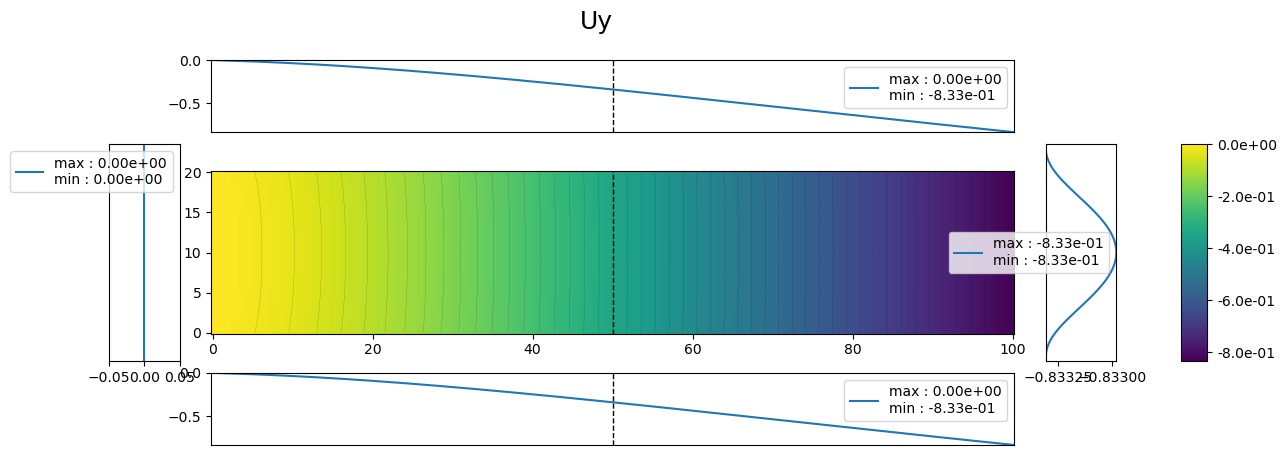

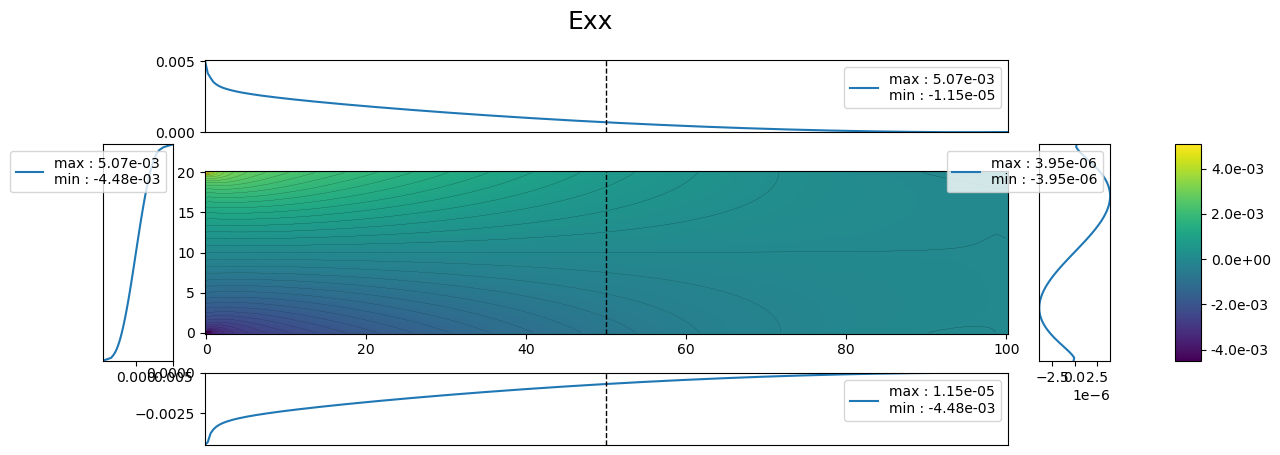

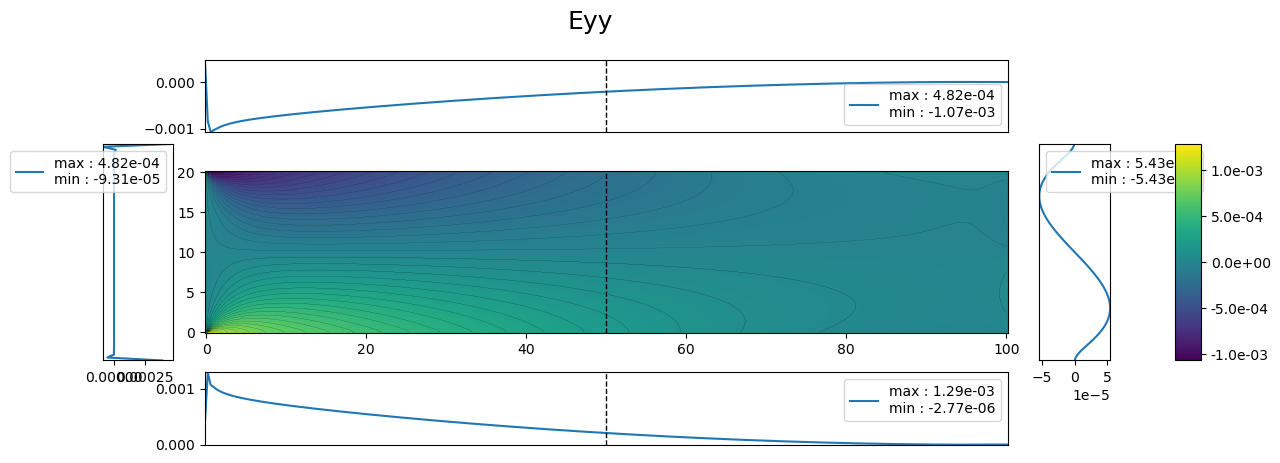

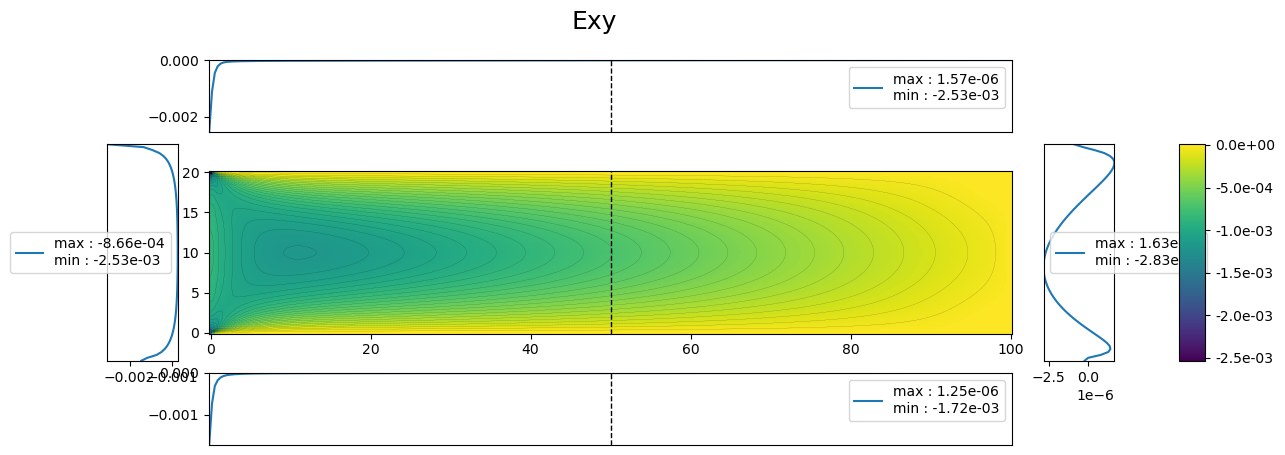

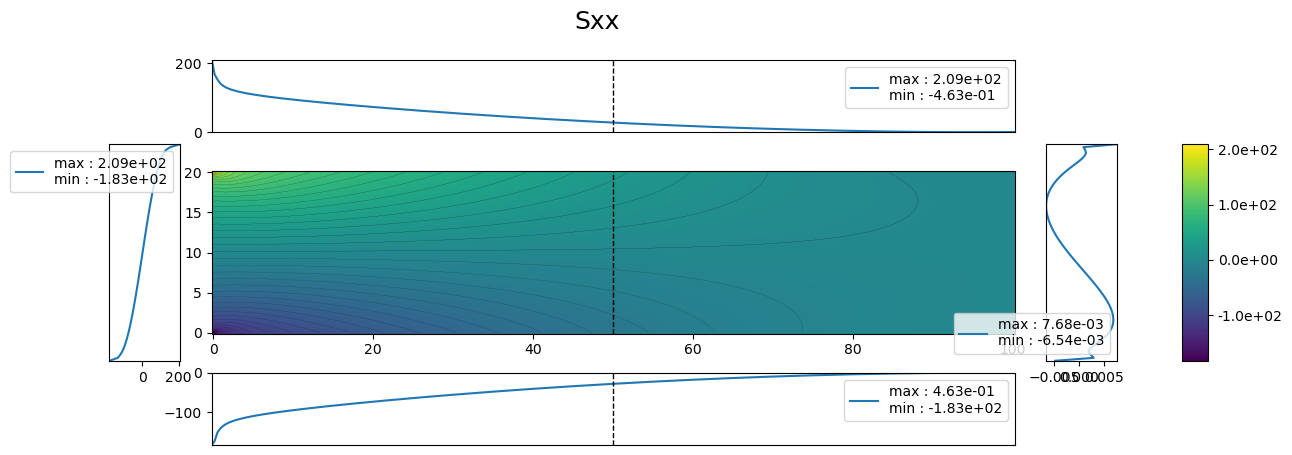

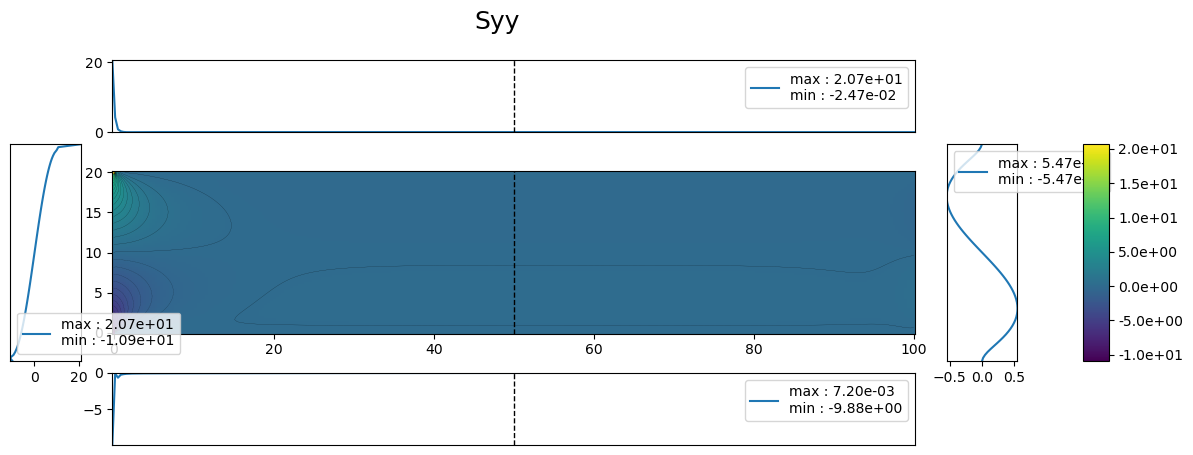

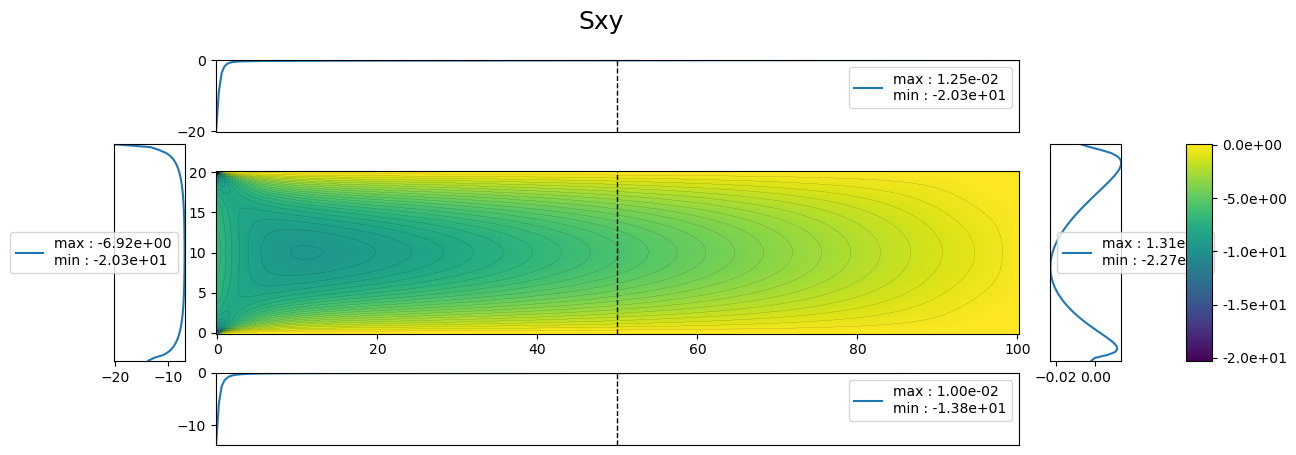

In [42]:
import matplotlib.ticker as ticker


def plot_boundary(F, F_bc, X, Y, title, axs):
    x_top = X[-1,:]
    x_bottom = X[0,:]
    y_left = Y[:,0]
    y_right = Y[:,-1]

    F_top = F_bc[-1,:]
    F_bottom = F_bc[0,:]
    F_left = F_bc[:,0]
    F_right = F_bc[:,-1]

    x_bcs = [x_top, x_bottom, F_left, F_right] 
    y_bcs = [F_top, F_bottom, y_left, y_right]

    index_bcs = [[0,1],[2,1],[1,0],[1,2]]

    axs[0][0].axis("off")
    axs[0][2].axis("off")
    axs[2][0].axis("off")
    axs[2][2].axis("off")

    for i, (x_bc, y_bc, ind) in enumerate(zip(x_bcs, y_bcs, index_bcs)):
        # axs[ind[0]][ind[1]].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.1e}"))
        ax = axs[ind[0]][ind[1]]
        if i<2:
            axs[ind[0]][ind[1]].plot(x_bc, y_bc, label=f"max : {np.max(y_bc):.2e}\nmin : {np.min(y_bc):.2e}")
            axs[ind[0]][ind[1]].xaxis.set_visible(False)
            axs[ind[0]][ind[1]].set_xlim([0, L_beam])
            axs[ind[0]][ind[1]].set_ylim([min(y_bc), max(y_bc)])
            #log scale
            # axs[ind[0]][ind[1]].set_yscale('log')
            ax.axvline(L_beam/2, color='k', linestyle='--', linewidth=1)

        else:
            axs[ind[0]][ind[1]].plot(x_bc, y_bc, label=f"max : {np.max(x_bc):.2e}\nmin : {np.min(x_bc):.2e}")
            axs[ind[0]][ind[1]].yaxis.set_visible(False)
            axs[ind[0]][ind[1]].set_ylim([0, w])
            axs[ind[0]][ind[1]].set_xlim([min(x_bc), max(x_bc)])
            #log scale
            # axs[ind[0]][ind[1]].set_xscale('log')
        axs[ind[0]][ind[1]].legend()
            
    im = pcolor_plot(axs[1][1], X, Y, F, None, colorbar=False)
    ax = axs[1][1]
    ax.axvline(L_beam/2, color='k', linestyle='--', linewidth=1)
    axs[1][1].set_zorder(-1)
    pos = axs[1][2].get_position()
    cax = fig.add_axes([pos.width + pos.x0 +0.05, pos.y0, 0.02, pos.height])
    fig.colorbar(im, cax=cax, format=ticker.FuncFormatter(lambda x, _: f"{x:.1e}"))
    plt.tight_layout()
    plt.suptitle(title, fontsize=18)

fields_exact = [u_val[:,0], u_val[:,1], strain_val[:,0], strain_val[:,1], strain_val[:,2], stress_val[:,0], stress_val[:,1], stress_val[:,2]]
titles = ["Ux", "Uy", "Exx", "Eyy", "Exy", "Sxx", "Syy", "Sxy"][:]

for title in titles:
    i = titles.index(title)

    field_exact = fields_exact[i].reshape(X.shape)
    field_exact_bc = fields_exact[i].reshape(X.shape)
    fig, axs = plt.subplots(3, 3, figsize=(13, 5), height_ratios=[0.2, 0.6, 0.2], width_ratios=[0.075, 0.85, 0.075], gridspec_kw={"hspace": 0.1, "wspace": 0.1})
    plot_boundary(field_exact, field_exact_bc, X, Y, title, axs)

In [9]:
# Save solution 
data_dir = "data_fem"
data_name = f"{material_type}_{X.shape[0]}x{X.shape[1]}"
data_path = f"{data_dir}/{data_name}"

# Save grid data
data_arrray = np.concatenate((X_grid, u_val, strain_val, stress_val), axis=1)
np.savetxt(data_path+".dat", data_arrray, delimiter=" ")

# Get the deformed coordinates
# coordinates = mesh.coordinates()
# u_mesh = np.array([uh(point) for point in coordinates])
# deformed_coordinates = coordinates + u_mesh
# deformed_coordinates_updown = coordinates + np.array([u_mesh[::-1,0], u_mesh[::-1,1]]).T

# # Save the mesh
# with open(data_path+".mesh", "w") as mesh_file:
#     # Write node data
#     mesh_file.write("*Part, name=Part-1\n*Nodes\n")
#     for idx, coord in enumerate(coordinates, start=1):
#         mesh_file.write(f"{idx};{coord[0]:.8f};{coord[1]:.8f};0.0\n")
    
#     # Write element data
#     mesh_file.write("*Elements\n")
#     for idx, cell in enumerate(mesh.cells(), start=1):
#         element_data = ";".join(str(node + 1) for node in cell)  # Add 1 to make node indices 1-based
#         mesh_file.write(f"{idx};{element_data}\n")

# #save the node data
# with open(data_path+".csv", "w") as node_file:
#     node_file.write("*Part, name=Part-1\n*Nodes\n")
#     for idx, coord in enumerate(deformed_coordinates, start=1):
#         node_file.write(f"{idx};{coord[0]:.8f};{coord[1]:.8f};0.0\n")

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 7700 and the array at index 1 has size 21375

In [233]:
from scipy.interpolate import RegularGridInterpolator

# Load solution
full_path = data_path + ".dat"
data = np.loadtxt(full_path, delimiter=" ")
n_rows, n_cols = map(int, full_path.replace('.dat', '').split('_')[-1].split('x'))

x_val      = data[:, 0]
y_val      = data[:, 1]
u_val = data[:, 2:4]
stress_val = data[:, 7:10]

solution_val = np.hstack((u_val, stress_val))

# Interpolate solution
x_grid = np.unique(x_val)
y_grid = np.unique(y_val)

interpolators = []
for i in range(solution_val.shape[1]):
    interp = RegularGridInterpolator((x_grid, y_grid), solution_val[:, i].reshape(n_rows, n_cols).T)
    interpolators.append(interp)

solution_fn = lambda x, y: np.array([interp((x, y)) for interp in interpolators]).T

In [8]:
# Check interpolation
n_plot_points = (100,77)
full_region = True

x_plot = np.linspace(0, L_beam, n_plot_points[0]) if full_region else np.linspace(J1L, J1L + gauge, n_plot_points[0])
y_plot = np.linspace(0, w, n_plot_points[1])
X, Y = np.meshgrid(x_plot, y_plot, indexing='ij')
X_grid = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

solution_plot = solution_fn(X_grid[:, 0], X_grid[:, 1])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
im = pcolor_plot(ax[0], X, Y, solution_plot[:,0].reshape(X.shape), "u_x",colormap=cmap)
im = pcolor_plot(ax[1], X, Y, solution_plot[:,1].reshape(X.shape), "u_y",colormap=cmap)

fig, ax = plt.subplots(1, 3, figsize=(21, 4))
im = pcolor_plot(ax[0], X, Y, solution_plot[:,2].reshape(X.shape), "sigma_xx",colormap=cmap)
im = pcolor_plot(ax[1], X, Y, solution_plot[:,3].reshape(X.shape), "sigma_yy",colormap=cmap)
im = pcolor_plot(ax[2], X, Y, solution_plot[:,4].reshape(X.shape), "sigma_xy",colormap=cmap)

NameError: name 'solution_fn' is not defined

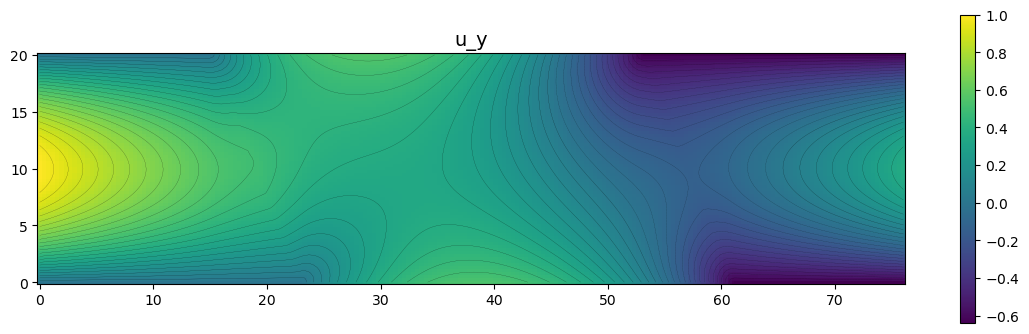

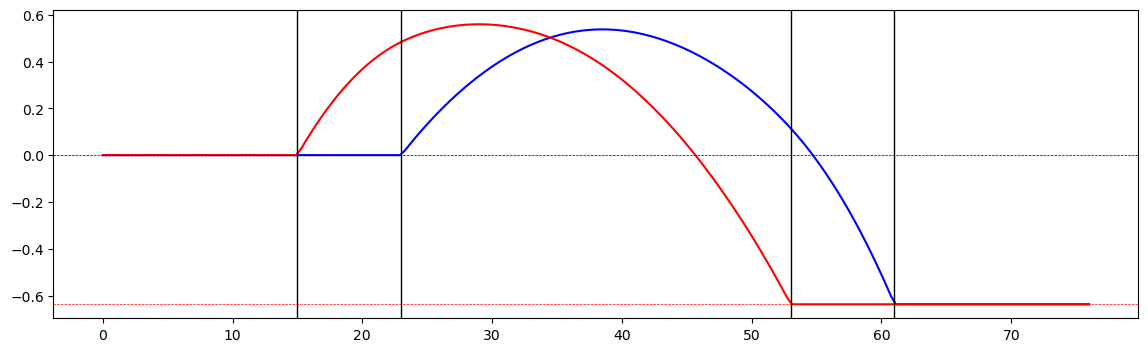

In [302]:
#check hard bc with 

# Check interpolation
n_plot_points = (200,77)
full_region = True

x_plot = np.linspace(0, Xmax, n_plot_points[0]) if full_region else np.linspace(J1L, J1L + gauge, n_plot_points[0])
# x_plot = np.linspace(0, J1S, n_plot_points[0])
y_plot = np.linspace(0, w, n_plot_points[1])
X, Y = np.meshgrid(x_plot, y_plot)
X_grid = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

def weighting(x1, x2,
              J1L, J1S, J2L, J2S,
              Xmax, w, k=10):
    """
    x1, x2 : np.ndarray of same shape
    J1L, J1S, J2L, J2S, Xmax, w : scalars
    k : steepness of each smooth step
    """

    # smooth‐step kernel (tanh‐based), maps ℝ→(0,1)
    s = lambda z: 0.5 * (np.tanh(k * z) + 1)

    # normalized height (0 at bottom, 1 at top)
    α = x2 / w
    β = 1 - α

    # ── four “clamp” factors ──
    #  f1 zeros only when (x2=0 AND x1<J1L)
    t1 = s(x1 - J1L)
    f1 =  t1 + α * (1 - t1)

    #  f2 zeros only when (x2=w AND x1<J1S)
    t2 = s(x1 - J1S)
    f2 =  t2 + β * (1 - t2)

    #  f3 zeros only when (x2=0 AND x1> Xmax–J2S)
    t3 = s(Xmax - J2S - x1)
    f3 =  t3 + α * (1 - t3)

    #  f4 zeros only when (x2=w AND x1> Xmax–J2L)
    t4 = s(Xmax - J2L - x1)
    f4 =  t4 + β * (1 - t4)

    return f1 * f2 * f3 * f4

from typing import List, Tuple, Literal

def boundary_constraint_factor(
    x1: np.ndarray,
    x2: np.ndarray,
    segments: List[Tuple[Tuple[float,float], Tuple[float,float]]],
    smoothness: Literal["C0", "C0+"] = "C0",
) -> np.ndarray:
    """
    x1, x2 : (n,) arrays of coordinates
    segments: list of ((xA,yA),(xB,yB))
    smoothness: "C0" = min distance, "C0+" = product of distances
    returns: (n,1) array
    """
    # helper: distance from (x1,x2) to segment A→B
    def _dist(A, B):
        xA, yA = A; xB, yB = B
        vx, vy = xB - xA, yB - yA
        # vector A→P
        px = x1 - xA
        py = x2 - yA
        t = np.clip((px*vx + py*vy) / (vx*vx + vy*vy), 0.0, 1.0)
        qx = xA + t*vx
        qy = yA + t*vy
        return np.hypot(x1 - qx, x2 - qy)[:, None]

    # build (n, m) matrix of distances
    D = np.hstack([ _dist(A, B) for A, B in segments ])

    raw = np.min(D, axis=1, keepdims=True)    if smoothness=="C0" else np.prod(D, axis=1, keepdims=True)
    return raw.flatten() / raw.max()

def Uy_bc(x1, x2, 
          J1L, J1S, J2L, J2S,
          Xmax, w, U=U_sol,
          coord_normalization=False, L=L):
    if coord_normalization:
        J1L, J1S, J2L, J2S = J1L / L, J1S / L, J2L / L, J2S / L
        Xmax = Xmax / L

    # compute start and end of ramp for each x2
    t = x2 / w                   # in [0, 1]
    start = J1L + (J1S - J1L) * t
    end   = (Xmax - J2S) + ((Xmax - J2L) - (Xmax - J2S)) * t

    Uy = np.zeros_like(x1, dtype=float)

    # above the end → full U
    Uy[x1 >= end] = U

    # in the ramp → linear interpolation
    ramp = (x1 > start) & (x1 < end)
    Uy[ramp] = ((x1[ramp] - start[ramp]) / (end[ramp] - start[ramp])) * U

    return Uy

segs = [
    ((0.0, 0.0), (J1L, 0.0)), # left bottom 
    ((0.0, w), (J1S, w)), # left top
    ((Xmax-J2S, 0.0), (Xmax, 0.0)), # right bottom
    ((Xmax-J2L, w), (Xmax, w)), # right top
]

fC0  = boundary_constraint_factor(X_grid[:, 0], X_grid[:, 1], segs, "C0")
fC0p = boundary_constraint_factor(X_grid[:, 0], X_grid[:, 1], segs, "C0+")

uy_test = np.ones(X_grid.shape[0])
uy_hard_bc = uy_test * weighting(X_grid[:, 0], X_grid[:, 1], J1L, J1S, J2L, J2S, Xmax, w, k=1) + Uy_bc(X_grid[:, 0], X_grid[:, 1], J1L, J1S, J2L, J2S, Xmax, w, U=float(U_sol), coord_normalization=False, L=L)
uy_hard_bc = uy_test * boundary_constraint_factor(X_grid[:, 0], X_grid[:, 1], segs, "C0+") + Uy_bc(X_grid[:, 0], X_grid[:, 1], J1L, J1S, J2L, J2S, Xmax, w, U=float(U_sol), coord_normalization=False, L=L)

# uy_hard_bc = Uy_bc(X_grid[:, 0], X_grid[:, 1], J1L=J1L, gauge=gauge, U=float(U_sol), coord_normalization=False, L=L)
fig, ax = plt.subplots(1, 1, figsize=(14, 4))
# im = pcolor_plot(ax[0], X, Y, uy_test.reshape(X.shape), "u_y",colormap=cmap)
im = pcolor_plot(ax, X, Y, uy_hard_bc.reshape(X.shape), "u_y",colormap=cmap)

# Plot the hard boundary condition
fig, ax = plt.subplots(1, 1, figsize=(14, 4))
plt.plot(x_plot, uy_hard_bc.reshape(X.shape)[0,:], label='Top Boundary Condition', color='blue')
plt.plot(x_plot, uy_hard_bc.reshape(X.shape)[-1,:], label='Bottom Boundary Condition', color='red')
ax.axhline(0, color='black', linestyle='--', linewidth=0.5)
ax.axhline(float(U_sol), color='red', linestyle='--', linewidth=0.5)
ax.axvline(J1S, color='k', linestyle='-', linewidth=1)
ax.axvline(J1L, color='k', linestyle='-', linewidth=1)
ax.axvline(Xmax - J2S, color='k', linestyle='-', linewidth=1)
ax.axvline(Xmax - J2L, color='k', linestyle='-', linewidth=1)

## Compare with VFM book

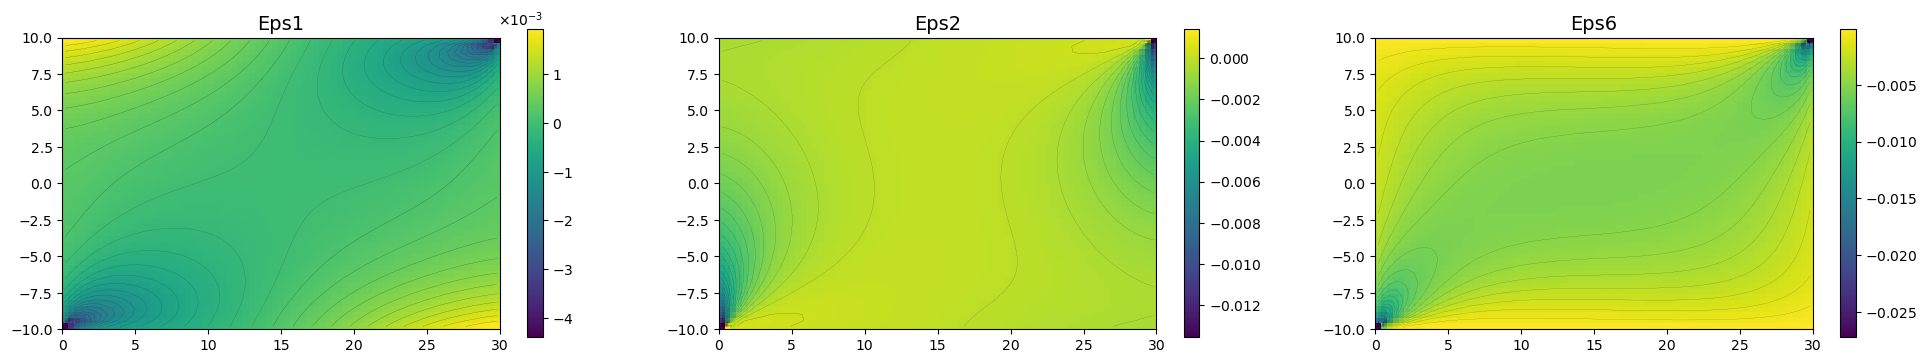

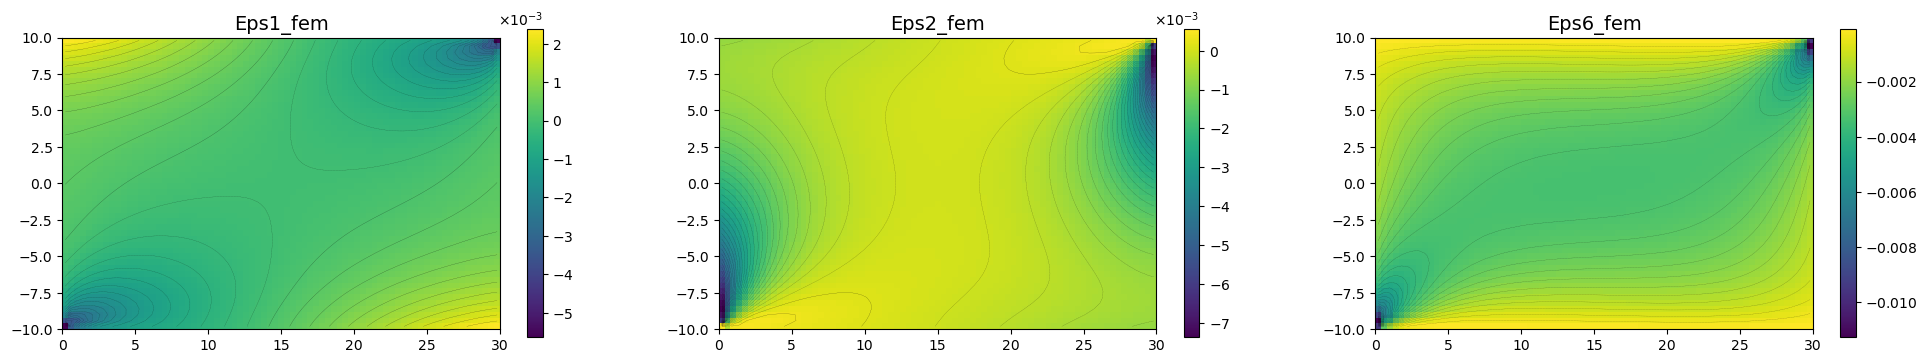

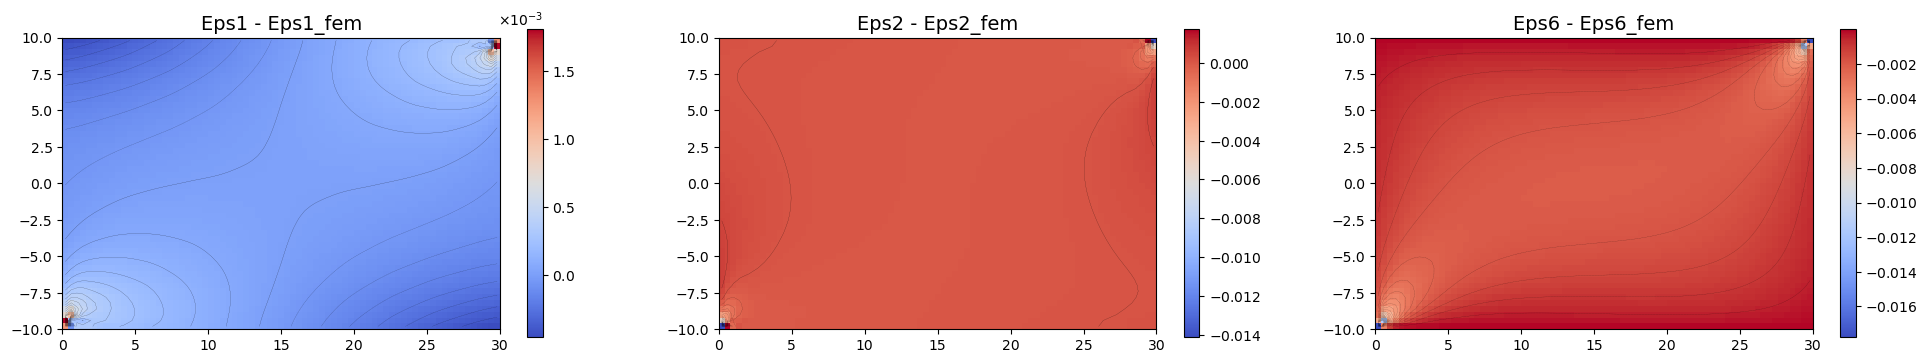

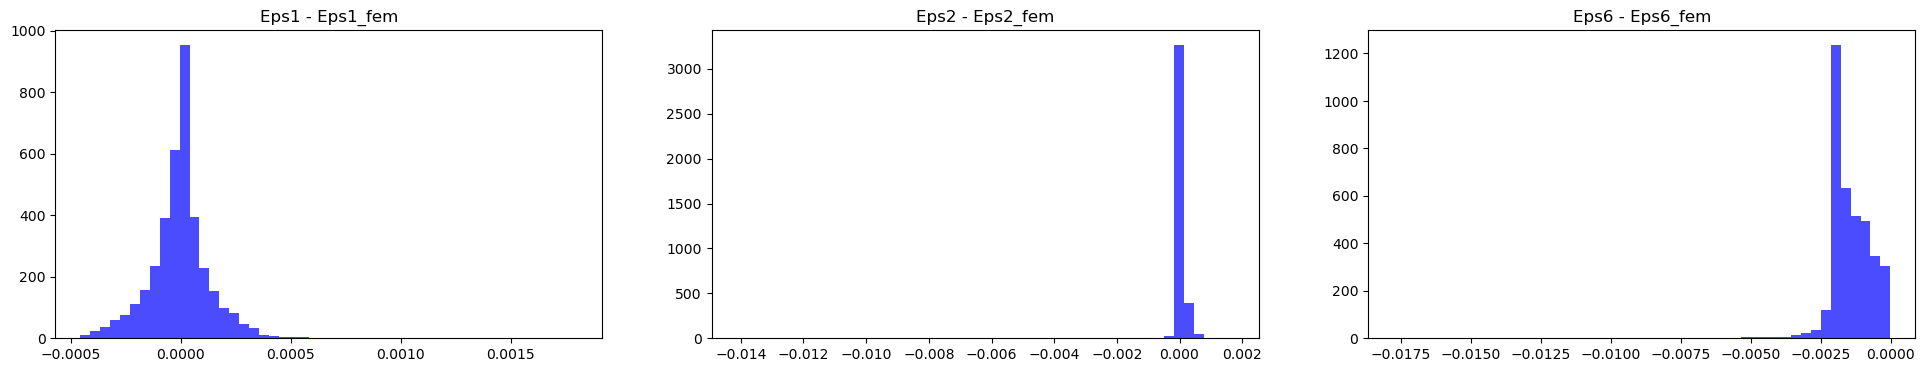

In [90]:
from scipy.io import loadmat

# Load the data
data_path = 'data/Iosipescu_isotropic.mat' if material_type == 'iso' else 'data/Iosipescu_orthotropic.mat'
data = loadmat(data_path)
X1 = data['X1']
X2 = data['X2']
L = float(data['L'].item())
w = float(data['w'].item())
t = float(data['t'].item())
F = float(data['F'].item())
Eps1 = data['Eps1']
Eps2 = data['Eps2']
Eps6 = data['Eps6']


Eps1_fem = np.array([strain([X1[i, j]+J1L, X2[i, j]+10])[0] for i in range(X1.shape[0]) for j in range(X1.shape[1])]).reshape(X1.shape)
Eps2_fem = np.array([strain([X1[i, j]+J1L, X2[i, j]+10])[3] for i in range(X1.shape[0]) for j in range(X1.shape[1])]).reshape(X1.shape)
Eps6_fem = np.array([strain([X1[i, j]+J1L, X2[i, j]+10])[1] for i in range(X1.shape[0]) for j in range(X1.shape[1])]).reshape(X1.shape)

# Plot the data
fig, ax = plt.subplots(1, 3, figsize=(24, 4))
im = pcolor_plot(ax[0], X1, X2, Eps1, "Eps1",colormap=cmap)
im = pcolor_plot(ax[1], X1, X2, Eps2, "Eps2",colormap=cmap)
im = pcolor_plot(ax[2], X1, X2, Eps6, "Eps6",colormap=cmap)
plt.show()

# Plot the FEM results
fig, ax = plt.subplots(1, 3, figsize=(24, 4))
im = pcolor_plot(ax[0], X1, X2, Eps1_fem, "Eps1_fem",colormap=cmap)
im = pcolor_plot(ax[1], X1, X2, Eps2_fem, "Eps2_fem",colormap=cmap)
im = pcolor_plot(ax[2], X1, X2, Eps6_fem, "Eps6_fem",colormap=cmap)
plt.show()

# Plot residuals
fig, ax = plt.subplots(1, 3, figsize=(24, 4))
im = pcolor_plot(ax[0], X1, X2, Eps1 - Eps1_fem, "Eps1 - Eps1_fem",colormap="coolwarm")
im = pcolor_plot(ax[1], X1, X2, Eps2 - Eps2_fem, "Eps2 - Eps2_fem",colormap="coolwarm")
im = pcolor_plot(ax[2], X1, X2, Eps6 - Eps6_fem, "Eps6 - Eps6_fem",colormap="coolwarm")
plt.show()

# Plot histograms of residuals
fig, ax = plt.subplots(1, 3, figsize=(24, 4))
ax[0].hist((Eps1 - Eps1_fem).flatten(), bins=50, color='blue', alpha=0.7)
ax[0].set_title("Eps1 - Eps1_fem")
ax[1].hist((Eps2 - Eps2_fem).flatten(), bins=50, color='blue', alpha=0.7)
ax[1].set_title("Eps2 - Eps2_fem")
ax[2].hist((Eps6 - Eps6_fem).flatten(), bins=50, color='blue', alpha=0.7)
ax[2].set_title("Eps6 - Eps6_fem")
plt.show()


## Check BC

/tmp/ipykernel_4866/3693197851.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


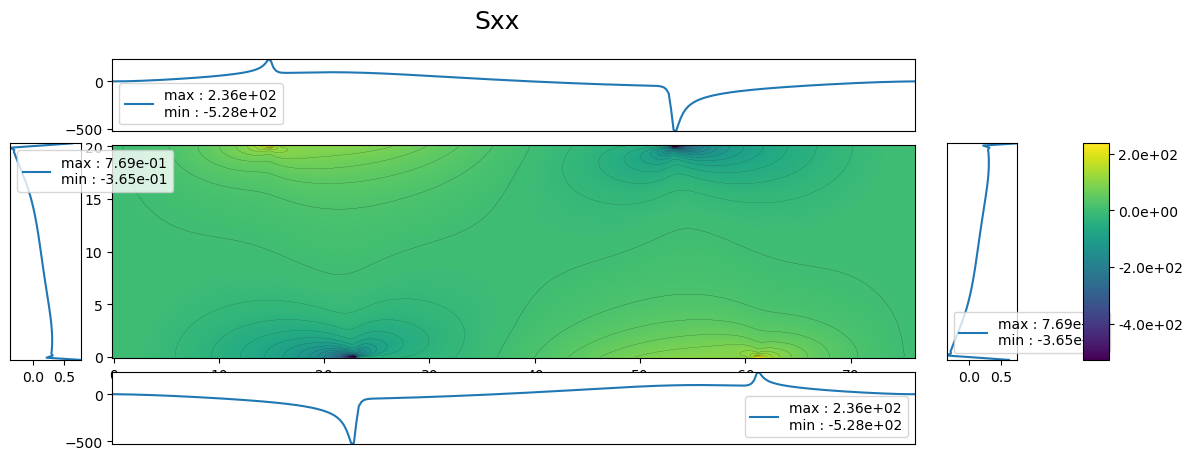

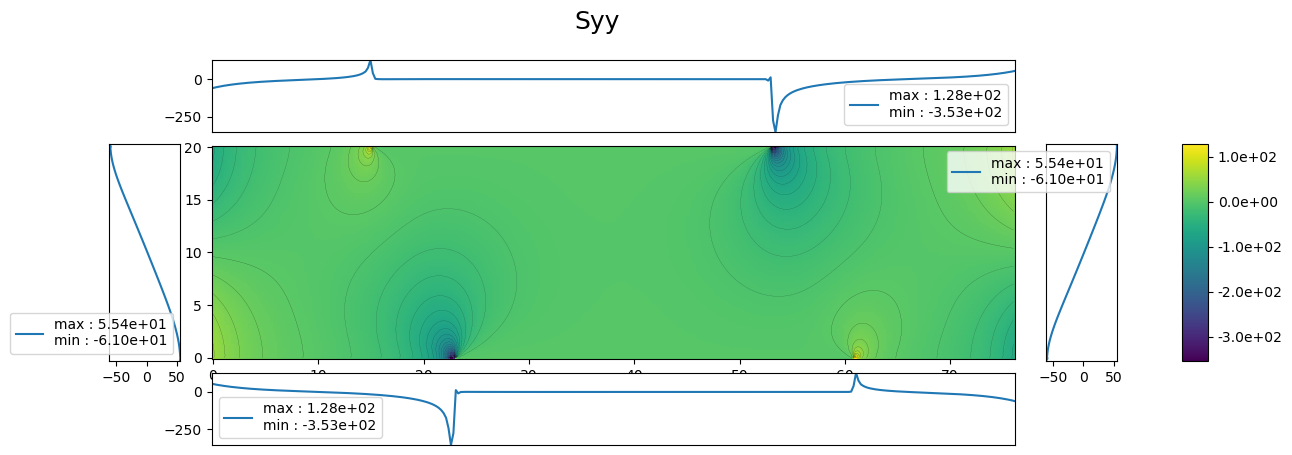

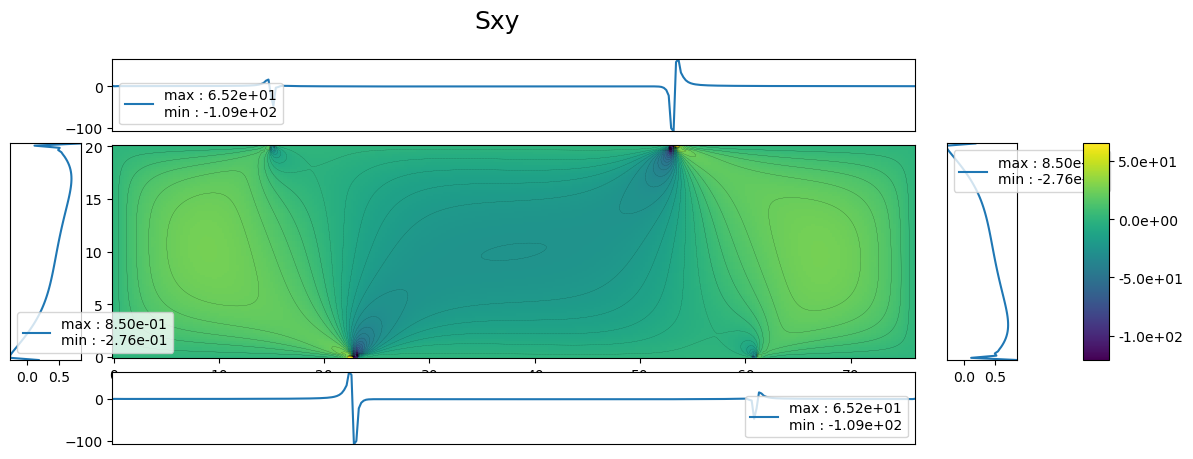

In [316]:
import matplotlib.ticker as ticker


def pcolor_plot(AX, X, Y, C, title, colormap="viridis", set_axis='on', colorbar=True, contour=True, n_levels=40, **kwargs):
    """
    Plots a pcolor plot with optional contour lines.
    
    Parameters:
        AX (matplotlib.axes): The axis to plot on.
        X, Y (2D array): Grid coordinates.
        C (2D array): Scalar field to plot.
        title (str): Plot title.
        colormap (str or Colormap): Colormap to use.
        set_axis (str): 'on' or 'off' to control axis visibility.
        colorbar (bool): Whether to display a colorbar.
        contour (bool): If True, adds contour lines.
        n_levels (int): Number of contour levels.
        kwargs: Optional `cmin` and `cmax` for color limits.
    """
    formatter = ticker.ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-3, 3))

    cmin = kwargs.get("cmin", None)
    cmax = kwargs.get("cmax", None)

    im = AX.pcolormesh(X, Y, C, cmap=colormap, shading='auto', vmin=cmin, vmax=cmax)

    if contour:
        levels = np.linspace(np.min(C) if cmin is None else cmin,
                             np.max(C) if cmax is None else cmax,
                             n_levels)
        AX.contour(X, Y, C, levels=levels, colors='k', linewidths=0.1)

    AX.set_aspect("equal", "box")
    AX.axis(set_axis)
    AX.set_title(title, fontsize=14)

    if colorbar:
        fig = AX.get_figure()
        fig.colorbar(im, ax=AX, format=formatter)

    return im

def plot_boundary(F, X, Y, title, axs):
    x_top = X[-1,:]
    x_bottom = X[0,:]
    y_left = Y[:,0]
    y_right = Y[:,-1]

    F_top = F[-1,:]
    F_bottom = F[0,:]
    F_left = F[:,0]
    F_right = F[:,-1]

    x_bcs = [x_top, x_bottom, F_left, F_right] 
    y_bcs = [F_top, F_bottom, y_left, y_right]

    index_bcs = [[0,1],[2,1],[1,0],[1,2]]

    axs[0][0].axis("off")
    axs[0][2].axis("off")
    axs[2][0].axis("off")
    axs[2][2].axis("off")

    for i, (x_bc, y_bc, ind) in enumerate(zip(x_bcs, y_bcs, index_bcs)):
        # axs[ind[0]][ind[1]].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.1e}"))
        if i<2:
            axs[ind[0]][ind[1]].plot(x_bc, y_bc, label=f"max : {np.max(y_bc):.2e}\nmin : {np.min(y_bc):.2e}")
            axs[ind[0]][ind[1]].xaxis.set_visible(False)
            axs[ind[0]][ind[1]].set_xlim([0, Xmax])
            axs[ind[0]][ind[1]].set_ylim([min(y_bc), max(y_bc)])
            #log scale
            # axs[ind[0]][ind[1]].set_yscale('log')

        else:
            axs[ind[0]][ind[1]].plot(x_bc, y_bc, label=f"max : {np.max(x_bc):.2e}\nmin : {np.min(x_bc):.2e}")
            axs[ind[0]][ind[1]].yaxis.set_visible(False)
            axs[ind[0]][ind[1]].set_ylim([0, w])
            axs[ind[0]][ind[1]].set_xlim([min(x_bc), max(x_bc)])
            #log scale
            # axs[ind[0]][ind[1]].set_xscale('log')
        axs[ind[0]][ind[1]].legend()
            
    im = pcolor_plot(axs[1][1], X, Y, F, None, colorbar=False)
    axs[1][1].set_zorder(-1)
    pos = axs[1][2].get_position()
    cax = fig.add_axes([pos.width + pos.x0 +0.05, pos.y0, 0.02, pos.height])
    fig.colorbar(im, cax=cax, format=ticker.FuncFormatter(lambda x, _: f"{x:.1e}"))
    plt.tight_layout()
    plt.suptitle(title, fontsize=18)

n_plot = (330, 100)
full_region = True

x_plot = np.linspace(0, Xmax, n_plot[0]) if full_region else np.linspace(J1L, J1L + gauge, n_plot[0])
y_plot = np.linspace(0, w, n_plot[1])
X, Y = np.meshgrid(x_plot, y_plot)

X_grid = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

u_val = np.array([uh(X_grid[i, :]) for i in range(X_grid.shape[0])])
strain_val = np.array([strain(X_grid[i, :]) for i in range(X_grid.shape[0])])
strain_val = np.array([strain_val[:,0], strain_val[:,3], 0.5*(strain_val[:,1]+strain_val[:,2])]).T
stress_val = np.array([stress(X_grid[i, :]) for i in range(X_grid.shape[0])])
stress_val = np.array([stress_val[:,0], stress_val[:,3], 0.5*(stress_val[:,1]+stress_val[:,2])]).T

solution_val = np.hstack((u_val, strain_val, stress_val))
fields_exact = [solution_val[:,i].reshape(X.shape) for i in range(8)]
fields_last = fields_exact[-3:]
# fields_last = [fields[i][-1].reshape(X.shape) for i in fields_plotted]
# fields_bc = fields_bc[-1:]
titles = ["Ux", "Uy", "Exx", "Eyy", "Exy", "Sxx", "Syy", "Sxy"][-3:]

for i,title in enumerate(titles):
    field_last = fields_last[i]#.reshape(X.shape)
    fig, axs = plt.subplots(3, 3, figsize=(13, 5), height_ratios=[0.2, 0.6, 0.2], width_ratios=[0.075, 0.85, 0.075], gridspec_kw={"hspace": 0.1, "wspace": 0.1})
    plot_boundary(field_last, X, Y, title, axs)